In [2]:
import numpy as np
import pandas as pd
import pyxlsb
import seaborn as sns


In [3]:
stctv = pd.read_excel("stc TV Data Set_T1.xlsb")

In [4]:
stctv.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 13 columns):
 #   Column            Non-Null Count    Dtype 
---  ------            --------------    ----- 
 0   Column1           1048575 non-null  int64 
 1   date_             1048575 non-null  int64 
 2   user_id_maped     1048575 non-null  int64 
 3   program_name      1048575 non-null  object
 4   duration_seconds  1048575 non-null  int64 
 5   program_class     1048575 non-null  object
 6   season            1048575 non-null  int64 
 7   episode           1048575 non-null  int64 
 8   program_desc      1034537 non-null  object
 9   program_genre     1048575 non-null  object
 10  series_title      1048575 non-null  int64 
 11  hd                1048575 non-null  int64 
 12  original_name     1048575 non-null  object
dtypes: int64(8), object(5)
memory usage: 104.0+ MB


In [8]:
stctv.head()

,date_,user_id_maped,program_name,duration_seconds,program_class,season,episode,program_desc,program_genre,series_title,hd,original_name
0,42882,26138,100 treets,40,MOVIE,0,0,Drama Movie100 Streets,Drama,0,0,100 treets
1,42876,7946,Moana,17,MOVIE,0,0,Animation MovieMoana (HD),Animation,0,1,Moana
2,42957,7418,The Mermaid Princess,8,MOVIE,0,0,Animation MovieThe Mermaid Princess (HD),Animation,0,1,The Mermaid Princess
3,42942,19307,The Mermaid Princess,76,MOVIE,0,0,Animation MovieThe Mermaid Princess (HD),Animation,0,1,The Mermaid Princess
4,42923,15860,Churchill,87,MOVIE,0,0,Biography MovieChurchill (HD),Biography,0,1,Churchill


In [17]:
# stctv.drop("Column1", axis=1, inplace=True)
#stctv["date_"] = pd.to_datetime(stctv["date_"], unit="D", origin="1899-12-30")
stctv["user_id_maped"] = stctv["user_id_maped"].astype(str)

In [ ]:
stctv.sort_values("date_", ascending=True)

,date_,user_id_maped,program_name,duration_seconds,program_class,season,episode,program_desc,program_genre,series_title,hd,original_name
0,2017-05-27,26138,100 treets,40,MOVIE,0,0,Drama Movie100 Streets,Drama,0,0,100 treets
1,2017-05-21,7946,Moana,17,MOVIE,0,0,Animation MovieMoana (HD),Animation,0,1,Moana
2,2017-08-10,7418,The Mermaid Princess,8,MOVIE,0,0,Animation MovieThe Mermaid Princess (HD),Animation,0,1,The Mermaid Princess
3,2017-07-26,19307,The Mermaid Princess,76,MOVIE,0,0,Animation MovieThe Mermaid Princess (HD),Animation,0,1,The Mermaid Princess
4,2017-07-07,15860,Churchill,87,MOVIE,0,0,Biography MovieChurchill (HD),Biography,0,1,Churchill


In [31]:
stctvML = stctv.groupby(["date_"]).agg(
    no_of_watches_perUser = ("user_id_maped","nunique") , 
    no_of_watches_tot = ("user_id_maped","count")
).reset_index()

In [32]:
stctvML

,date_,no_of_watches_perUser,no_of_watches_tot
0,2017-03-14,558,3462
1,2017-03-15,536,3446
2,2017-03-16,630,3524
3,2017-03-17,708,4260
4,2017-03-18,699,4241
...,...,...,...
406,2018-04-26,336,2475
407,2018-04-27,330,2352
408,2018-04-28,339,2534
409,2018-04-29,315,2272


In [34]:
import matplotlib.pyplot as plt 
import plotly 
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [36]:
figureOne = px.line(stctvML, x= "date_", y="no_of_watches_tot", title="Number Of Watches")
figureOne.show()

In [38]:
figureTwo = px.line(stctvML, x="date_",y="no_of_watches_perUser", title="unique no of watches")
figureTwo.show()

In [40]:
from prophet import Prophet

In [42]:
stctvMLX = stctvML[["date_","no_of_watches_tot"]].copy()
stctvMLX.columns = ["ds", "y"]

In [49]:
model = Prophet(weekly_seasonality=False)
model.fit(stctvMLX)


22:16:57 - cmdstanpy - INFO - Chain [1] start processing
22:16:57 - cmdstanpy - INFO - Chain [1] done processing


In [50]:
future = model.make_future_dataframe(periods=245)
forecast = model.predict(future)

C:\Users\Turki\AppData\Local\Temp\ipykernel_18552\2107326233.py:2: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



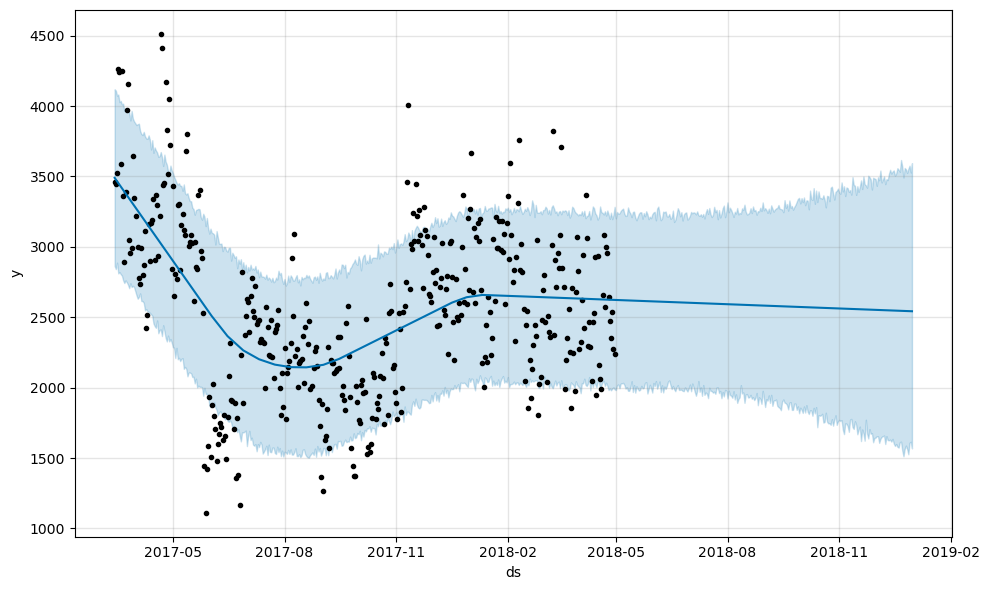

In [51]:
fig = model.plot(forecast)
fig.show()